# **Experiment Notebook**

**Climate Comfort Index (CCI) – 3-day regression**

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
# <Student to fill this section>
student_name = "Arsh Ashfaqhusein Mansuri"
student_id = "25522436"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
# <Student to fill this section>
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# Custom package from AT1 (shiftguard), extended for AT2 and published to TestPyPI
# %pip install -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple shiftguard
import shiftguard
from shiftguard import adversarial_auc
from shiftguard.weather import (
    build_features, ClimatologyBaseline, persistence_forecast, scores_table,
    compute_cci, cci_band, regression_scores,
)

from weather_experiments.config import (
    RAW_DATA_DIR, PROCESSED_DATA_DIR, MODELS_DIR, FIGURES_DIR, REPORTS_DIR,
    PRODUCTION_CUTOFF, VAL_START, TEST_START, SEED,
)
from weather_experiments.features import build_model_table, select_groups, EXCLUDED_BASE_VARS

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("shiftguard", shiftguard.__version__)
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Ridge

HORIZONS = (1, 2, 3)
TARGETS = [f"target_cci_t{h}" for h in HORIZONS]
from shiftguard.weather.targets import CCI_BANDS

2026-09-27 14:20:30.235 | INFO     | weather_experiments.config:<module>:11 - PROJ_ROOT path is: /Users/arsh/Desktop/Adv_ML_AT2/36120-26SP-AT2-25522436-experiments


shiftguard 0.2.0


---
## A. Project Description


In [8]:
# <Student to fill this section>
business_use_case_description = """
Explain clearly what is the goal of this project for the business.
"""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
# <Student to fill this section>
business_objectives = """
What will be the impact of accurate or incorrect results?
"""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
# <Student to fill this section>
stakeholders_expectations_explanations = """
How will the results be used?
Who will be the users of your predictions? Who will be impacted by your predictions?
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## B. Experiment Hypothesis

In [14]:
# <Student to fill this section>
experiment_hypothesis = """
TODO (testable): e.g. 'A gradient boosting regressor using lag, rolling-window and calendar features achieves at least 10% lower MAE than the climatology baseline (test MAE ~7.5) for CCI at t+1 on the 2023-2025 test set.'
"""

In [15]:
# Do not modify this code
print_tile(size="h3", key='experiment_hypothesis', value=experiment_hypothesis)

---
## C. Data Understanding

### C.1   Load Raw Data


In [16]:
# <Student to fill this section>
# Built by `uv run python -m weather_experiments.dataset`: hourly Open-Meteo archive data (1980-2025)
# for Sydney, aggregated to daily values. Nothing on/after the production cut-off is loaded.
daily_df = pd.read_parquet(PROCESSED_DATA_DIR / "sydney_daily.parquet")
assert daily_df.index.max() < pd.Timestamp(PRODUCTION_CUTOFF)
daily_df.head()

,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,snowfall,wind_gusts_10m,temperature_2m_max,temperature_2m_min,precipitation_hours,...,shortwave_radiation,wind_u,wind_v,cci,whi,whc,target_cci_t1,target_cci_t2,target_cci_t3,target_whc_t7
date,,,,,,,,,,,,,,,,,,,,,
1980-01-01,21.204167,85.291667,15.212500,99.583333,14.3,0.0,45.7,23.1,19.4,15.0,...,137.958333,-5.036943,13.250119,56.873437,48.245000,1,52.284375,60.406250,64.096875,1
1980-01-02,20.158333,88.708333,10.441667,98.291667,18.8,0.0,31.3,21.9,19.3,24.0,...,106.333333,-4.057265,8.168493,52.284375,48.585000,1,60.406250,64.096875,81.223958,0
1980-01-03,21.587500,82.000000,7.625000,90.875000,15.4,0.0,35.6,23.6,19.6,5.0,...,194.958333,-7.082028,0.211677,60.406250,44.420000,1,64.096875,81.223958,75.800521,1
1980-01-04,22.041667,86.583333,9.541667,72.666667,13.5,0.0,48.6,25.7,20.2,11.0,...,187.958333,0.714975,-0.222901,64.096875,42.630000,1,81.223958,75.800521,72.734896,0
1980-01-05,21.200000,72.041667,12.041667,51.958333,0.0,0.0,37.1,23.9,19.0,0.0,...,323.541667,-0.760570,10.584489,81.223958,21.841667,0,75.800521,72.734896,76.068750,0


### C.2 Define Target variable

In [17]:
# <Student to fill this section>
# The target formula lives in the shiftguard package so the notebook and the API share it.
print(inspect.getsource(compute_cci))

def compute_cci(df: pd.DataFrame) -> pd.Series:
    """Compute the Climate Comfort Index (0-100) from daily aggregated weather.

    Expects daily mean ``temperature_2m``, ``relative_humidity_2m``, ``wind_speed_10m`` and
    ``cloud_cover``, and daily total ``precipitation``.
    """
    temp = np.maximum(0, 1 - (df["temperature_2m"] - 22).abs() / 20)
    humidity = np.maximum(0, 1 - (df["relative_humidity_2m"] - 50).abs() / 50)
    wind = np.maximum(0, 1 - (df["wind_speed_10m"] - 10).abs() / 40)
    cloud = np.maximum(0, 1 - df["cloud_cover"] / 100)
    rain = np.maximum(0, 1 - df["precipitation"] / 20)
    cci = 100 * (0.35 * temp + 0.20 * humidity + 0.15 * wind + 0.15 * cloud + 0.15 * rain)
    return cci.rename("cci")



In [18]:
# <Student to fill this section>
target_definition_explanations = """
TODO: CCI formula (component scores + weights), daily aggregation (mean temperature/humidity/wind/cloud, total precipitation), 0-100 range. The ML targets are CCI at t+1, t+2 and t+3 for an input date t.
Explain the rationale on the definition of the target variable according to your business use case.
"""

In [19]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable


In [20]:
# <Student to fill this section>
daily_df["cci"] = compute_cci(daily_df)
for h in (1, 2, 3):
    daily_df[f"target_cci_t{h}"] = daily_df["cci"].shift(-h)

target_name = 'target_cci_t1'
# The last input dates have no target: their t+h date falls in 2026 (production data, never loaded).
daily_df[["cci"] + TARGETS].tail(4)

,cci,target_cci_t1,target_cci_t2,target_cci_t3
date,,,,
2025-12-28,77.773958,85.546354,81.814583,71.664062
2025-12-29,85.546354,81.814583,71.664062,NaN
2025-12-30,81.814583,71.664062,NaN,NaN
2025-12-31,71.664062,NaN,NaN,NaN


### C.4 Explore Target variable

{'count': 16802.0, 'mean': 72.56, 'std': 10.09, 'min': 28.63, '25%': 67.01, '50%': 73.53, '75%': 79.29, 'max': 98.89}
{'Comfortable conditions': 66.5, 'Excellent outdoor conditions': 22.7, 'Moderate comfort': 10.3, 'Poor comfort': 0.5}


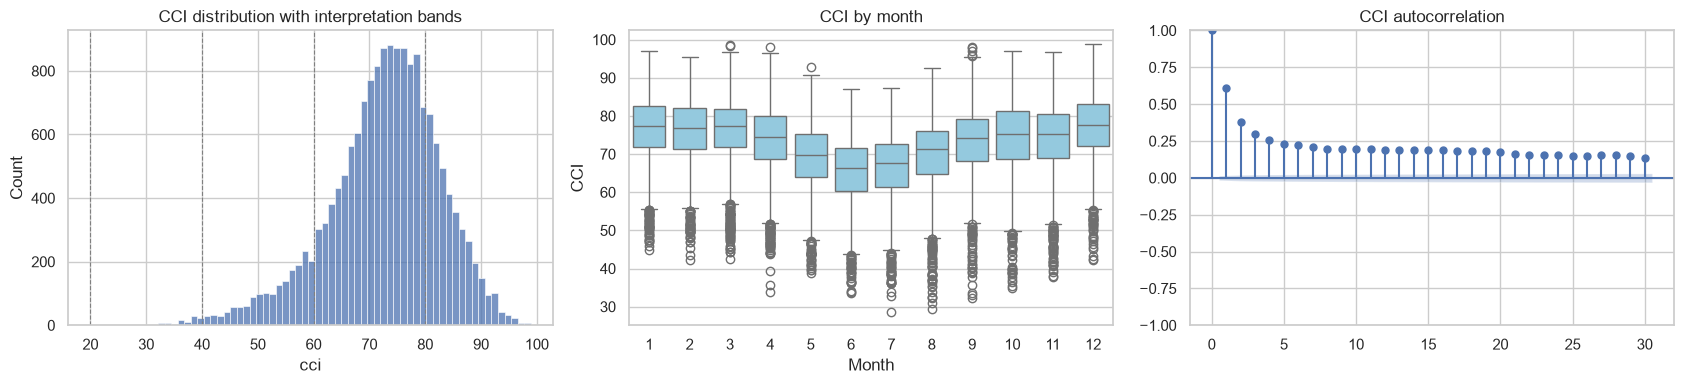

In [21]:
# <Student to fill this section>
cci = daily_df["cci"]
print(cci.describe().round(2).to_dict())
print((cci.apply(cci_band).value_counts(normalize=True) * 100).round(1).to_dict())
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(cci, bins=60, ax=axes[0])
for x in (20, 40, 60, 80):
    axes[0].axvline(x, ls="--", c="grey", lw=0.8)
axes[0].set_title("CCI distribution with interpretation bands")
sns.boxplot(x=cci.index.month, y=cci.values, ax=axes[1], color="skyblue")
axes[1].set(title="CCI by month", xlabel="Month", ylabel="CCI")
plot_acf(cci, lags=30, ax=axes[2]); axes[2].set_title("CCI autocorrelation")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_target_overview.png", dpi=120); plt.show()

In [22]:
# <Student to fill this section>
print("CCI autocorrelation at lag 1/2/3/7:", [round(cci.autocorr(lag), 2) for lag in (1, 2, 3, 7)])
components = pd.DataFrame({
    "TempScore": (1 - (daily_df["temperature_2m"] - 22).abs() / 20).clip(lower=0),
    "HumidityScore": (1 - (daily_df["relative_humidity_2m"] - 50).abs() / 50).clip(lower=0),
    "WindScore": (1 - (daily_df["wind_speed_10m"] - 10).abs() / 40).clip(lower=0),
    "CloudScore": (1 - daily_df["cloud_cover"] / 100).clip(lower=0),
    "RainScore": (1 - daily_df["precipitation"] / 20).clip(lower=0),
})
weights = pd.Series({"TempScore": .35, "HumidityScore": .20, "WindScore": .15, "CloudScore": .15, "RainScore": .15})
pd.DataFrame({"mean_score": components.mean(), "std_score": components.std(),
              "std_of_weighted_contribution": (components * weights * 100).std()}).round(3)

CCI autocorrelation at lag 1/2/3/7: [np.float64(0.61), np.float64(0.38), np.float64(0.3), np.float64(0.21)]


,mean_score,std_score,std_of_weighted_contribution
TempScore,0.742,0.176,6.169
HumidityScore,0.563,0.196,3.914
WindScore,0.920,0.073,1.097
CloudScore,0.523,0.301,4.522
RainScore,0.912,0.203,3.040


In [23]:
# <Student to fill this section>
target_distribution_explanations = """
provide a detailed analysis on the target variable, its distribution, limitations, issues, ...
"""

In [24]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `temperature_2m`

daily mean, °C – 35% of the CCI weight

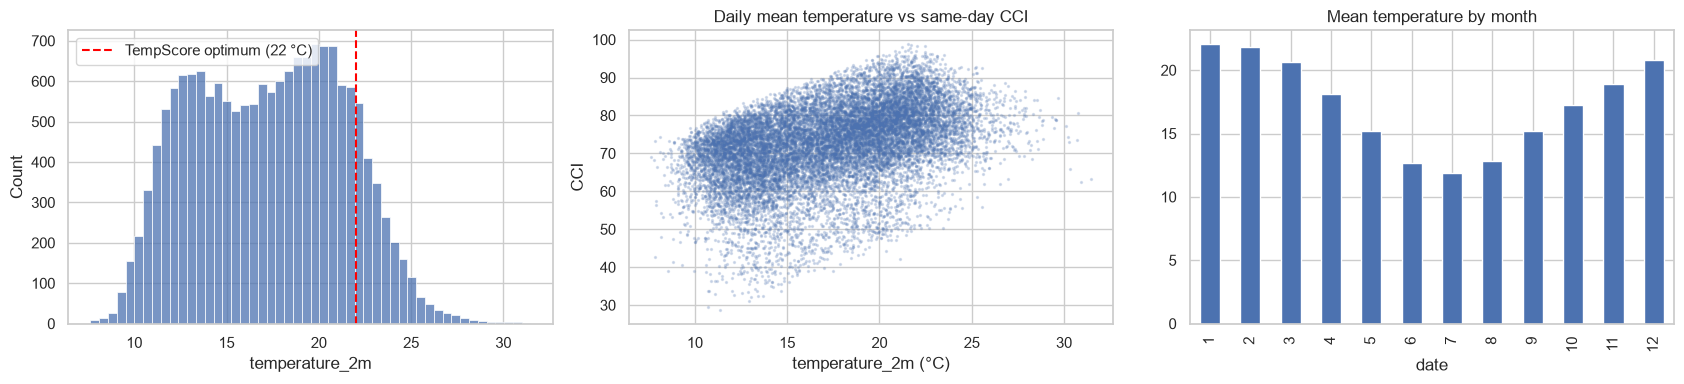

count    16802.00
mean        17.25
std          4.06
min          7.62
25%         13.79
50%         17.37
75%         20.47
max         31.48
Name: temperature_2m, dtype: float64

In [25]:
# <Student to fill this section>
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(daily_df["temperature_2m"], bins=50, ax=axes[0])
axes[0].axvline(22, c="red", ls="--", label="TempScore optimum (22 °C)"); axes[0].legend()
axes[1].scatter(daily_df["temperature_2m"], daily_df["cci"], s=2, alpha=0.2)
axes[1].set(xlabel="temperature_2m (°C)", ylabel="CCI", title="Daily mean temperature vs same-day CCI")
daily_df.groupby(daily_df.index.month)["temperature_2m"].mean().plot(kind="bar", ax=axes[2], title="Mean temperature by month")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_temperature.png", dpi=120); plt.show()
daily_df["temperature_2m"].describe().round(2)

In [26]:
# <Student to fill this section>
# How much of each input still relates to the target 1-3 days ahead?
inputs = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "cloud_cover", "precipitation"]
pd.DataFrame({t: daily_df[inputs].corrwith(daily_df[t]) for t in ["cci"] + TARGETS}).round(3)

,cci,target_cci_t1,target_cci_t2,target_cci_t3
temperature_2m,0.416,0.355,0.327,0.325
relative_humidity_2m,-0.596,-0.367,-0.206,-0.133
wind_speed_10m,-0.087,0.015,0.027,0.019
cloud_cover,-0.639,-0.317,-0.115,-0.041
precipitation,-0.566,-0.266,-0.103,-0.052


In [27]:
# <Student to fill this section>
feature_1_insights = """
provide a detailed analysis on the selected feature, its distribution, limitations, issues, ...
"""

In [28]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `relative_humidity_2m`

daily mean, %

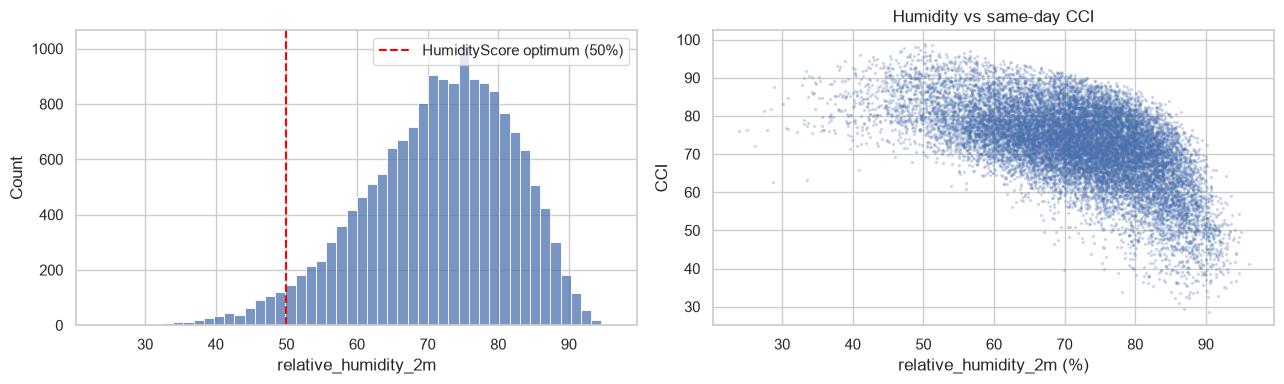

{'count': 16802.0, 'mean': 71.48, 'std': 10.6, 'min': 23.88, '25%': 64.83, '50%': 72.67, '75%': 79.29, 'max': 96.04}
Share of days with humidity above 50%: 96.4


In [29]:
# <Student to fill this section>
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(daily_df["relative_humidity_2m"], bins=50, ax=axes[0])
axes[0].axvline(50, c="red", ls="--", label="HumidityScore optimum (50%)"); axes[0].legend()
axes[1].scatter(daily_df["relative_humidity_2m"], daily_df["cci"], s=2, alpha=0.2)
axes[1].set(xlabel="relative_humidity_2m (%)", ylabel="CCI", title="Humidity vs same-day CCI")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_humidity.png", dpi=120); plt.show()
print(daily_df["relative_humidity_2m"].describe().round(2).to_dict())
print("Share of days with humidity above 50%:", round((daily_df["relative_humidity_2m"] > 50).mean() * 100, 1))

In [30]:
# <Student to fill this section>
feature_2_insights = """
provide a detailed analysis on the selected feature, its distribution, limitations, issues, ...
"""

In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `precipitation`

daily total, mm

Dry days (<=0.1 mm): 56.5% | days >= 20 mm (RainScore = 0): 2.1%


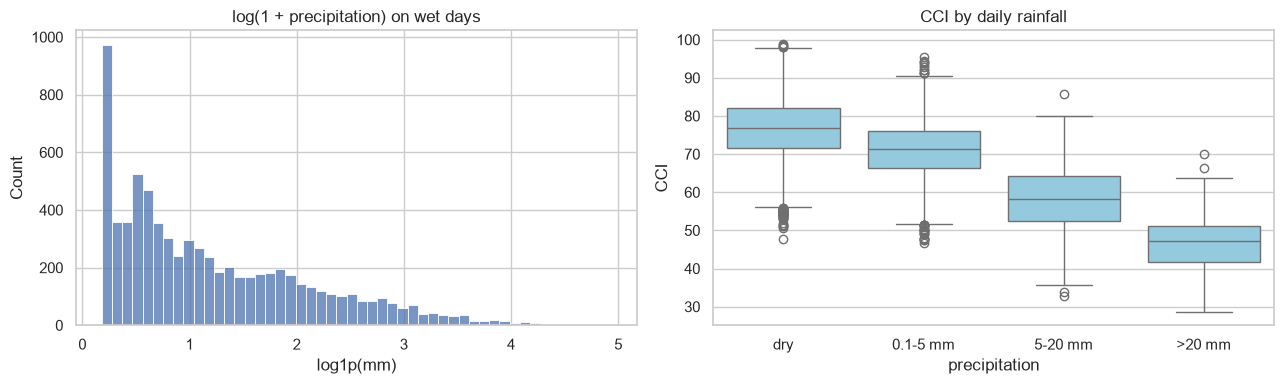

In [32]:
# <Student to fill this section>
precip = daily_df["precipitation"]
wet = precip > 0.1
print(f"Dry days (<=0.1 mm): {(~wet).mean():.1%} | days >= 20 mm (RainScore = 0): {(precip >= 20).mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(np.log1p(precip[wet]), bins=50, ax=axes[0]); axes[0].set(title="log(1 + precipitation) on wet days", xlabel="log1p(mm)")
sns.boxplot(x=pd.cut(precip, [-0.01, 0.1, 5, 20, 1000], labels=["dry", "0.1-5 mm", "5-20 mm", ">20 mm"]),
            y=daily_df["cci"], ax=axes[1], color="skyblue")
axes[1].set(title="CCI by daily rainfall", xlabel="precipitation", ylabel="CCI")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_precipitation.png", dpi=120); plt.show()

In [33]:
# <Student to fill this section>
precip.sort_values(ascending=False).head(5).round(1)

date
2020-02-09    138.4
1992-02-09    130.0
1990-02-03    128.3
1987-11-11    118.0
1990-02-04    105.6
Name: precipitation, dtype: float64

In [34]:
# <Student to fill this section>
feature_n_insights = """
provide a detailed analysis on the selected feature, its distribution, limitations, issues, ...
"""

In [35]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.8 Explore Remaining Features

wind_speed_10m, cloud_cover and the extra predictors (dew point, pressure, radiation, wind components)

> You can add more cells related to other feeatures in this section

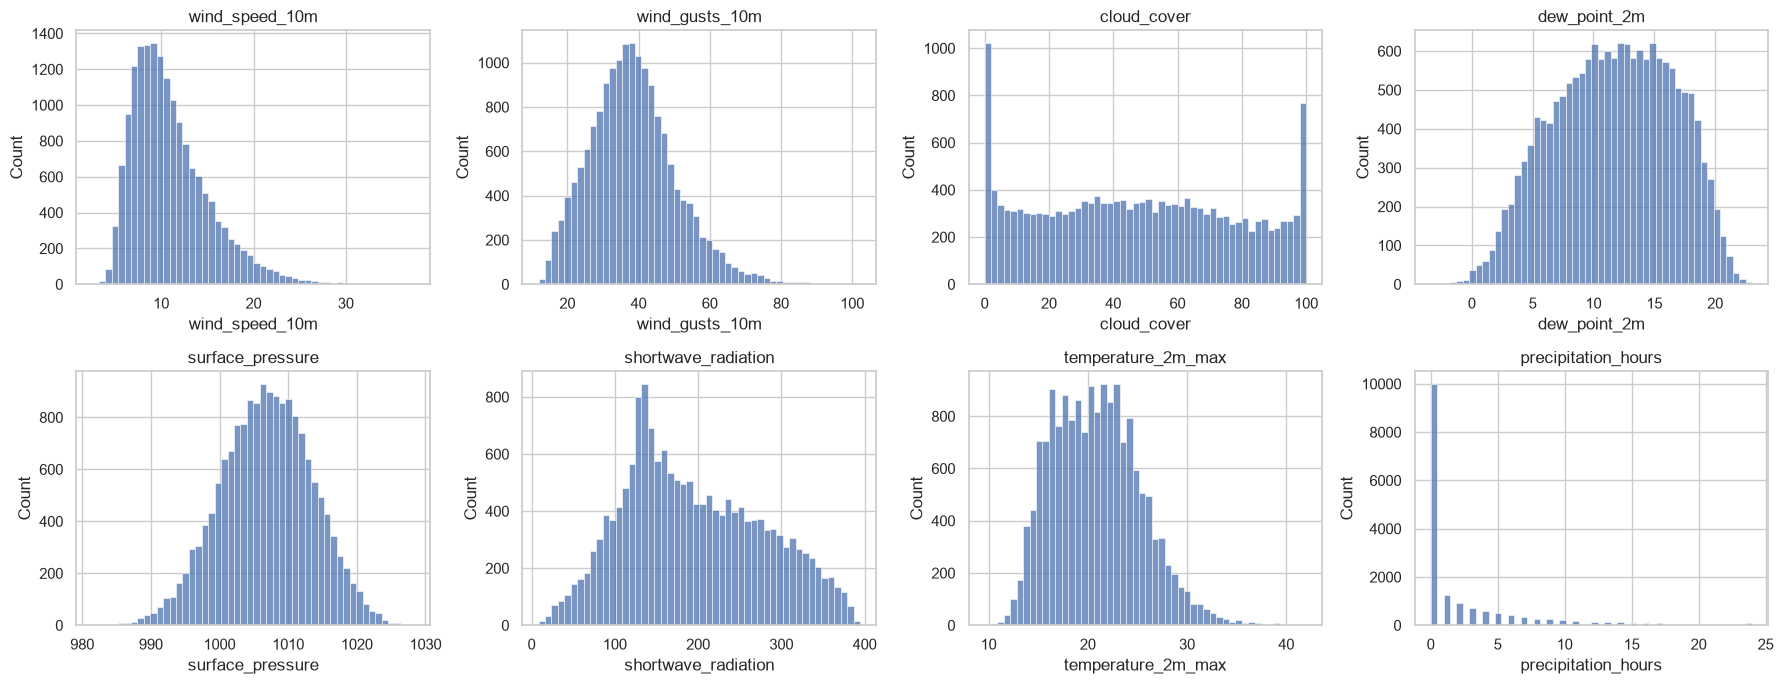

,count,mean,std,min,25%,50%,75%,max
wind_speed_10m,16802.0,11.01,4.21,2.55,7.94,10.13,13.18,37.39
wind_gusts_10m,16802.0,38.53,12.11,11.90,30.20,37.80,45.40,102.20
cloud_cover,16802.0,47.66,30.14,0.00,22.00,47.04,72.17,100.00
dew_point_2m,16802.0,11.65,4.85,-3.38,7.95,11.84,15.53,23.05
surface_pressure,16802.0,1006.82,6.69,981.50,1002.27,1006.91,1011.48,1028.32
shortwave_radiation,16802.0,194.01,83.55,8.38,130.42,182.44,257.92,394.50
temperature_2m_max,16802.0,20.84,4.46,9.60,17.30,20.60,23.80,42.00
precipitation_hours,16802.0,2.52,4.69,0.00,0.00,0.00,3.00,24.00


In [36]:
# <Student to fill this section>
other_vars = ["wind_speed_10m", "wind_gusts_10m", "cloud_cover", "dew_point_2m",
              "surface_pressure", "shortwave_radiation", "temperature_2m_max", "precipitation_hours"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, var in zip(axes.ravel(), other_vars):
    sns.histplot(daily_df[var], bins=50, ax=ax)
    ax.set_title(var)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_other_features.png", dpi=120); plt.show()
daily_df[other_vars].describe().T.round(2)

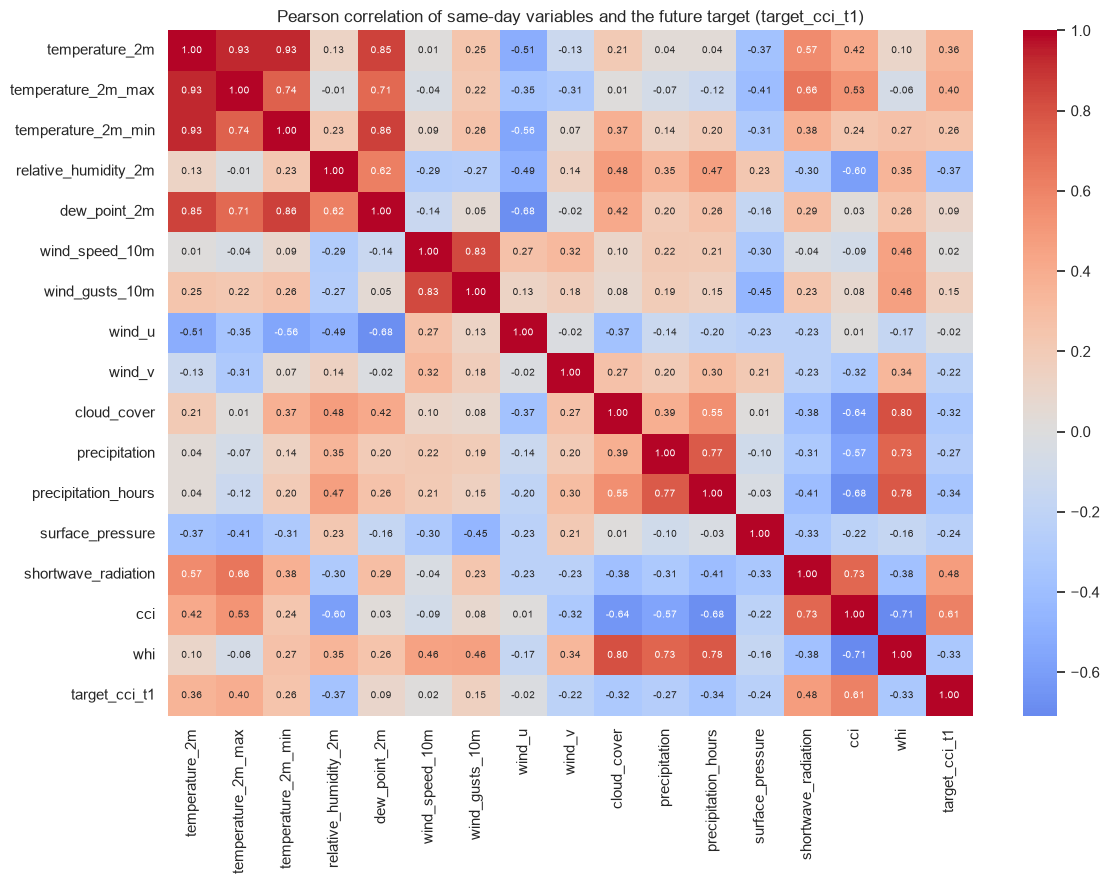

In [37]:
# <Student to fill this section>
base_vars = ["temperature_2m", "temperature_2m_max", "temperature_2m_min", "relative_humidity_2m",
             "dew_point_2m", "wind_speed_10m", "wind_gusts_10m", "wind_u", "wind_v", "cloud_cover",
             "precipitation", "precipitation_hours", "surface_pressure", "shortwave_radiation",
             "cci", "whi", "target_cci_t1"]
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(daily_df[base_vars].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Pearson correlation of same-day variables and the future target (target_cci_t1)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_correlation_heatmap.png", dpi=120); plt.show()

---
## D. Feature Selection



### D.1 Approach "Correlation and Mutual Information with the Target"

In [38]:
# <Student to fill this section>
model_table, all_features = build_model_table(daily_df)
print(len(all_features), "candidate features built by shiftguard.build_features (details in section F)")
# Selection statistics are computed on the training period only so validation/test stay unseen.
sel = model_table.loc[model_table.index < VAL_START].dropna(subset=["target_cci_t1"])
rank = pd.DataFrame({
    "abs_pearson": sel[all_features].corrwith(sel["target_cci_t1"]).abs(),
    "mutual_info": mutual_info_regression(sel[all_features], sel["target_cci_t1"], random_state=SEED),
}, index=all_features)
group_of = {c: g for g in ["raw", "lags", "rolling", "calendar"] for c in select_groups(all_features, [g])}
rank["group"] = rank.index.map(group_of)
rank.sort_values("mutual_info", ascending=False).head(15).round(3)

161 candidate features built by shiftguard.build_features (details in section F)


,abs_pearson,mutual_info,group
cci,0.607,0.256,raw
cci_roll3_mean,0.511,0.158,rolling
shortwave_radiation,0.480,0.154,raw
cci_roll7_mean,0.448,0.140,rolling
temperature_2m_max_roll3_mean,0.395,0.135,rolling
temperature_2m_max,0.406,0.133,raw
shortwave_radiation_roll3_mean,0.437,0.130,rolling
shortwave_radiation_roll7_mean,0.407,0.130,rolling
temperature_2m_max_roll7_mean,0.392,0.116,rolling
shortwave_radiation_roll14_mean,0.394,0.114,rolling


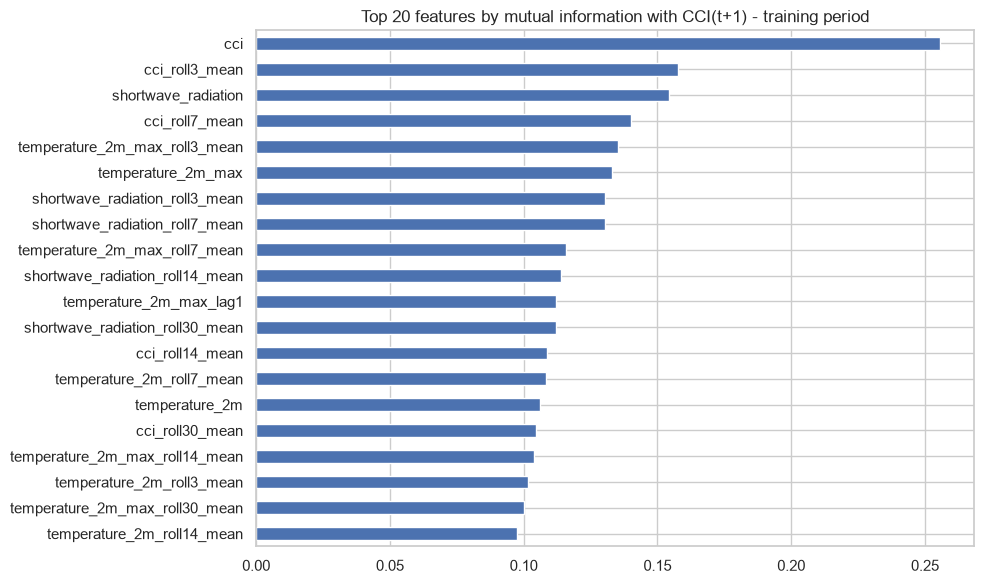

abs_pearson        mutual_info       
                mean    max        mean    max
group                                         
calendar       0.213  0.360       0.054  0.097
lags           0.161  0.372       0.032  0.112
raw            0.281  0.607       0.075  0.256
rolling        0.213  0.511       0.048  0.158

In [39]:
# <Student to fill this section>
fig, ax = plt.subplots(figsize=(10, 6))
rank.sort_values("mutual_info").tail(20)["mutual_info"].plot(kind="barh", ax=ax, title="Top 20 features by mutual information with CCI(t+1) - training period")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_mutual_information.png", dpi=120); plt.show()
rank.groupby("group")[["abs_pearson", "mutual_info"]].agg(["mean", "max"]).round(3)

In [40]:
# <Student to fill this section>
feature_selection_1_insights = """
provide an explanation on why you use this approach for feature selection and describe its results
"""

In [41]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Permutation Importance from a Tree Ensemble (validation set)"

In [42]:
# <Student to fill this section>
val_sel = model_table.loc[(model_table.index >= VAL_START) & (model_table.index < TEST_START)].dropna(subset=["target_cci_t1"])
probe = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                     colsample_bytree=0.5, random_state=SEED, n_jobs=-1).fit(sel[all_features], sel["target_cci_t1"])
perm = permutation_importance(probe, val_sel[all_features], val_sel["target_cci_t1"],
                              scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED)
perm_imp = pd.Series(perm.importances_mean, index=all_features).sort_values(ascending=False)
print("Features whose shuffling does not increase validation MAE:", int((perm_imp <= 0).sum()), "of", len(perm_imp))
perm_imp.groupby(perm_imp.index.map(group_of)).sum().round(3)

Features whose shuffling does not increase validation MAE: 79 of 161


calendar    0.031
lags        0.054
raw         2.211
rolling    -0.086
dtype: float64

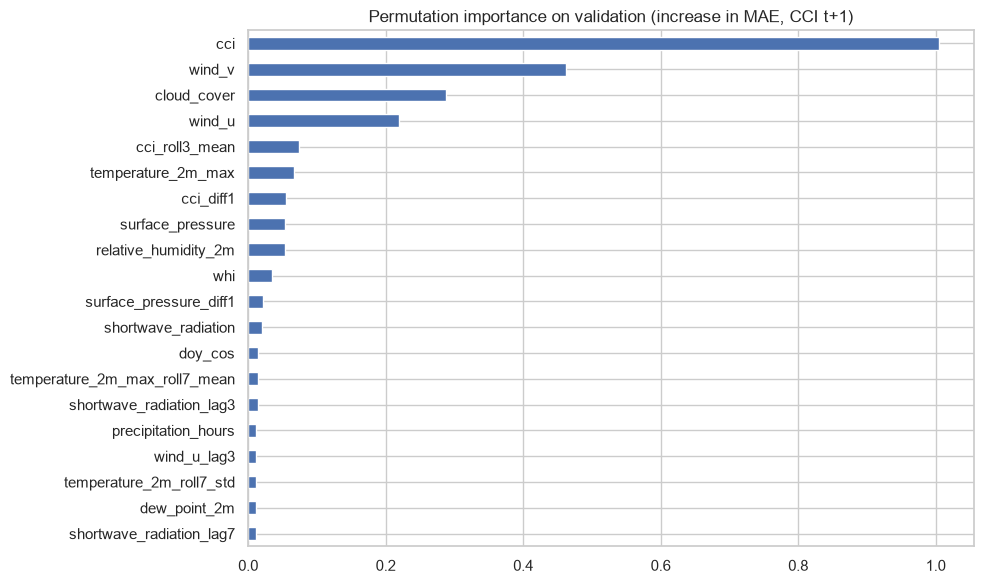

In [43]:
# <Student to fill this section>
fig, ax = plt.subplots(figsize=(10, 6))
perm_imp.head(20).sort_values().plot(kind="barh", ax=ax, title="Permutation importance on validation (increase in MAE, CCI t+1)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_permutation_importance.png", dpi=120); plt.show()

In [44]:
# <Student to fill this section>
feature_selection_2_insights = """
provide an explanation on why you use this approach for feature selection and describe its results
"""

In [45]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.3 Approach "Multicollinearity Check and Feature-Group Ablation"

> You can add more cells related to other approaches in this section

In [46]:
# <Student to fill this section>
corr_matrix = sel[all_features].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
high_pairs = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print(len(high_pairs), "feature pairs with |r| > 0.95")
high_pairs.head(10).round(3)

46 feature pairs with |r| > 0.95


precipitation_roll3_mean       precipitation_roll3_sum           1.000
precipitation_roll14_mean      precipitation_roll14_sum          1.000
precipitation_roll30_mean      precipitation_roll30_sum          1.000
precipitation_roll7_mean       precipitation_roll7_sum           1.000
temperature_2m_roll30_mean     temperature_2m_min_roll30_mean    0.986
temperature_2m_roll14_mean     temperature_2m_min_roll14_mean    0.981
temperature_2m_roll30_mean     temperature_2m_max_roll30_mean    0.981
temperature_2m_min_roll7_mean  temperature_2m_min_roll14_mean    0.980
temperature_2m_lag1            temperature_2m_roll3_mean         0.979
temperature_2m_roll7_mean      temperature_2m_roll14_mean        0.979
dtype: float64

In [47]:
# <Student to fill this section>
# Feature-group ablation: same XGBoost settings, trained on 1980-2019, scored on validation.
def xgb_probe():
    return XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5, min_child_weight=10,
                        subsample=0.8, colsample_bytree=0.5, random_state=SEED, n_jobs=-1)

train_sel = model_table.loc[model_table.index < VAL_START]
val_all = model_table.loc[(model_table.index >= VAL_START) & (model_table.index < TEST_START)]
ablation_sets = {
    "raw": ["raw"], "raw+lags": ["raw", "lags"], "raw+lags+rolling": ["raw", "lags", "rolling"],
    "raw+lags+calendar": ["raw", "lags", "calendar"], "all groups": ["raw", "lags", "rolling", "calendar"],
}
ablation = {}
for name, groups in ablation_sets.items():
    cols = select_groups(all_features, groups)
    row = {"n_features": len(cols)}
    for target in TARGETS:
        tr, va = train_sel.dropna(subset=[target]), val_all.dropna(subset=[target])
        pred = np.clip(xgb_probe().fit(tr[cols], tr[target]).predict(va[cols]), 0, 100)
        row[f"val_mae_{target[-2:]}"] = regression_scores(va[target], pred)["mae"]
    ablation[name] = row
ablation = pd.DataFrame(ablation).T
ablation.round(3)

,n_features,val_mae_t1,val_mae_t2,val_mae_t3
raw,16.0,6.152,7.547,8.028
raw+lags,85.0,6.060,7.388,7.876
raw+lags+rolling,157.0,6.074,7.511,7.884
raw+lags+calendar,89.0,6.046,7.466,7.825
all groups,161.0,6.102,7.493,7.879


## D.z Final Selection of Features


In [48]:
# <Student to fill this section>
features_list = select_groups(all_features, ["raw", "lags", "calendar"])
print(len(features_list), "features selected")

89 features selected


In [49]:
# <Student to fill this section>
pd.Series(features_list).groupby(pd.Series(features_list).map(group_of)).size()

calendar     4
lags        69
raw         16
dtype: int64

In [50]:
# <Student to fill this section>
feature_selection_explanations = """
provide a quick explanation on the features selected
"""

In [51]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "Remove incomplete days"

In [52]:
# <Student to fill this section>
hourly = pd.read_parquet(RAW_DATA_DIR / "sydney_hourly_1980_2025.parquet")
hours_per_day = hourly.groupby(hourly["time"].dt.date).size()
print("Hours per day (count of days):", hours_per_day.value_counts().to_dict())
print("Missing hourly values:", int(hourly.drop(columns="time").isna().sum().sum()))
weather_cols = [c for c in daily_df.columns if not c.startswith("target_")]
print("Missing daily values (excluding shifted targets):", int(daily_df[weather_cols].isna().sum().sum()))
steps = daily_df.index.to_series().diff().dropna()
print("Continuous daily index:", bool((steps == pd.Timedelta("1D")).all()),
      "|", daily_df.index.min().date(), "->", daily_df.index.max().date(), "|", len(daily_df), "days")

Hours per day (count of days): {24: 16802}
Missing hourly values: 0
Missing daily values (excluding shifted targets): 0
Continuous daily index: True | 1980-01-01 -> 2025-12-31 | 16802 days


In [53]:
# <Student to fill this section>
data_cleaning_1_explanations = """
Provide some explanations on why you believe it is important to fix this issue and its impacts
"""

In [54]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "Validate physical ranges"

In [55]:
# <Student to fill this section>
bounds = {
    "temperature_2m": (-5, 45), "temperature_2m_max": (-5, 50), "temperature_2m_min": (-10, 40),
    "relative_humidity_2m": (0, 100), "dew_point_2m": (-30, 35),
    "wind_speed_10m": (0, 150), "wind_gusts_10m": (0, 250), "cloud_cover": (0, 100),
    "precipitation": (0, 500), "surface_pressure": (900, 1100), "shortwave_radiation": (0, 1400),
}
range_checks = pd.DataFrame({
    var: {"min": daily_df[var].min(), "max": daily_df[var].max(), "lower_bound": lo, "upper_bound": hi,
          "violations": int(((daily_df[var] < lo) | (daily_df[var] > hi)).sum())}
    for var, (lo, hi) in bounds.items()
}).T
assert range_checks["violations"].sum() == 0
range_checks

,min,max,lower_bound,upper_bound,violations
temperature_2m,7.625000,31.479167,-5.0,45.0,0.0
temperature_2m_max,9.600000,42.000000,-5.0,50.0,0.0
temperature_2m_min,1.100000,27.700000,-10.0,40.0,0.0
relative_humidity_2m,23.875000,96.041667,0.0,100.0,0.0
dew_point_2m,-3.379167,23.045833,-30.0,35.0,0.0
wind_speed_10m,2.554167,37.387500,0.0,150.0,0.0
wind_gusts_10m,11.900000,102.200000,0.0,250.0,0.0
cloud_cover,0.000000,100.000000,0.0,100.0,0.0
precipitation,0.000000,138.400000,0.0,500.0,0.0
surface_pressure,981.495833,1028.325000,900.0,1100.0,0.0


In [56]:
# <Student to fill this section>
data_cleaning_2_explanations = """
Provide some explanations on why you believe it is important to fix this issue and its impacts
"""

In [57]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "Drop constant variables (snowfall)"

In [58]:
# <Student to fill this section>
print("Snowfall summary (cm):", daily_df["snowfall"].describe().round(3).to_dict())
print("Days with snowfall > 0:", int((daily_df["snowfall"] > 0).sum()))
print("Excluded from the feature set:", EXCLUDED_BASE_VARS)

Snowfall summary (cm): {'count': 16802.0, 'mean': 0.0, 'std': 0.0, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 0.0}
Days with snowfall > 0: 0
Excluded from the feature set: {'snowfall'}


In [59]:
# <Student to fill this section>
data_cleaning_3_explanations = """
Provide some explanations on why you believe it is important to fix this issue and its impacts
"""

In [60]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.4 Data Issue "Open-Meteo source change in 2017"

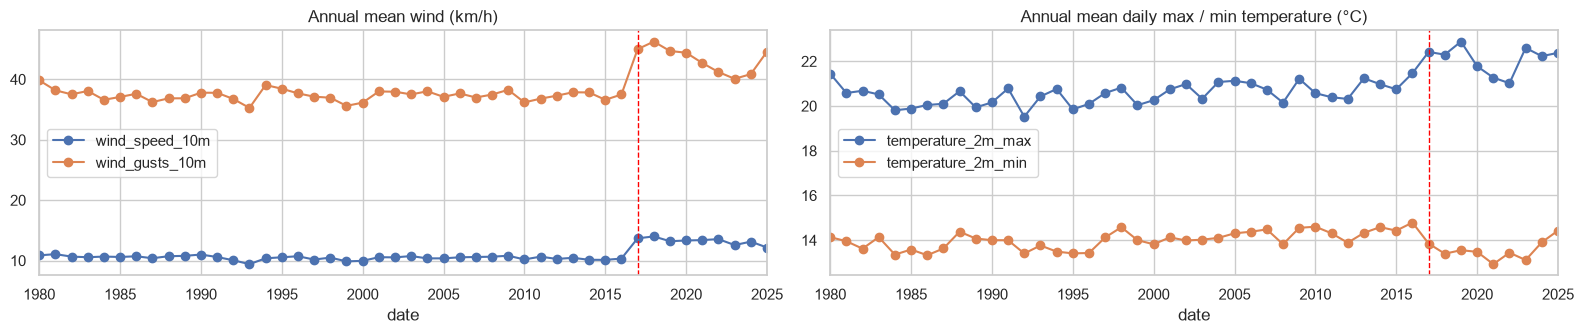

{'wind_speed_10m': 10.5, 'wind_gusts_10m': 37.4} (before 2017)
{'wind_speed_10m': 13.2, 'wind_gusts_10m': 43.3} (2017 onwards)


,adversarial_auc
1980-1999 vs 2000-2016,0.561
2000-2016 vs 2017-2025,0.914
train (<2020) vs test (2023-2025),0.845


In [61]:
# <Student to fill this section>
annual = daily_df[["wind_speed_10m", "wind_gusts_10m", "temperature_2m_max", "temperature_2m_min"]].resample("YE").mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5))
annual[["wind_speed_10m", "wind_gusts_10m"]].plot(ax=axes[0], marker="o", title="Annual mean wind (km/h)")
annual[["temperature_2m_max", "temperature_2m_min"]].plot(ax=axes[1], marker="o", title="Annual mean daily max / min temperature (°C)")
for ax in axes:
    ax.axvline(pd.Timestamp("2017-01-01"), color="red", ls="--", lw=1)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_source_step_change.png", dpi=120); plt.show()

same_day = ["temperature_2m", "temperature_2m_max", "temperature_2m_min", "relative_humidity_2m",
            "dew_point_2m", "wind_speed_10m", "wind_gusts_10m", "cloud_cover", "precipitation",
            "surface_pressure", "shortwave_radiation"]
periods = {
    "1980-1999 vs 2000-2016": (daily_df.loc["1980":"1999"], daily_df.loc["2000":"2016"]),
    "2000-2016 vs 2017-2025": (daily_df.loc["2000":"2016"], daily_df.loc["2017":"2025"]),
    "train (<2020) vs test (2023-2025)": (daily_df.loc[:"2019"], daily_df.loc["2023":"2025"]),
}
drift = pd.DataFrame({
    name: {"adversarial_auc": adversarial_auc(a[same_day], b[same_day], random_state=SEED)}
    for name, (a, b) in periods.items()
}).T.round(3)
print(daily_df.loc[:"2016", ["wind_speed_10m", "wind_gusts_10m"]].mean().round(1).to_dict(), "(before 2017)")
print(daily_df.loc["2017":, ["wind_speed_10m", "wind_gusts_10m"]].mean().round(1).to_dict(), "(2017 onwards)")
drift

In [62]:
# <Student to fill this section>
data_cleaning_4_explanations = """
TBD
"""

In [63]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_4_explanations', value=data_cleaning_4_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Lag features"

All features use only information available on or before the input date *t*.

In [64]:
# <Student to fill this section>
acf_vars = ["cci", "whi", "temperature_2m", "relative_humidity_2m", "wind_gusts_10m",
            "cloud_cover", "precipitation", "surface_pressure"]
acf_table = pd.DataFrame({v: [daily_df[v].autocorr(lag) for lag in (1, 2, 3, 7, 14)] for v in acf_vars},
                         index=["lag1", "lag2", "lag3", "lag7", "lag14"]).round(2)
lag_cols = [c for c in all_features if "_lag" in c or "_diff" in c]
print(len(lag_cols), "lag / difference features, e.g.", lag_cols[:6])
acf_table

69 lag / difference features, e.g. ['temperature_2m_lag1', 'temperature_2m_lag2', 'temperature_2m_lag3', 'temperature_2m_lag7', 'temperature_2m_diff1', 'temperature_2m_max_lag1']


,cci,whi,temperature_2m,relative_humidity_2m,wind_gusts_10m,cloud_cover,precipitation,surface_pressure
lag1,0.61,0.49,0.91,0.66,0.44,0.50,0.39,0.79
lag2,0.38,0.20,0.84,0.39,0.24,0.24,0.13,0.49
lag3,0.30,0.10,0.81,0.28,0.17,0.16,0.06,0.32
lag7,0.21,0.05,0.79,0.17,0.19,0.09,0.02,0.21
lag14,0.19,0.05,0.77,0.15,0.18,0.09,0.02,0.16


In [65]:
# <Student to fill this section>
# Leakage test: changing everything *after* a date must not change that date's features.
check_date = pd.Timestamp("2010-06-15")
perturbed = daily_df.copy()
future = perturbed.index > check_date
num_cols = perturbed.select_dtypes("number").columns
perturbed.loc[future, num_cols] = perturbed.loc[future, num_cols] + 100
original_row = build_features(daily_df).loc[check_date, all_features]
perturbed_row = build_features(perturbed).loc[check_date, all_features]
assert np.allclose(original_row.astype(float), perturbed_row.astype(float), equal_nan=True)
assert (model_table["temperature_2m_lag1"] == daily_df["temperature_2m"].shift(1).reindex(model_table.index)).all()
print("No look-ahead: features on", check_date.date(), "are unchanged when all later data is altered.")

No look-ahead: features on 2010-06-15 are unchanged when all later data is altered.


In [66]:
# <Student to fill this section>
feature_engineering_1_explanations = """
Provide some explanations on why you believe it is important to create this feature and its impacts
"""

In [67]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Trailing rolling-window statistics"

72 rolling features, e.g. ['temperature_2m_roll3_mean', 'temperature_2m_roll7_mean', 'temperature_2m_roll14_mean', 'temperature_2m_roll30_mean', 'temperature_2m_roll7_std']


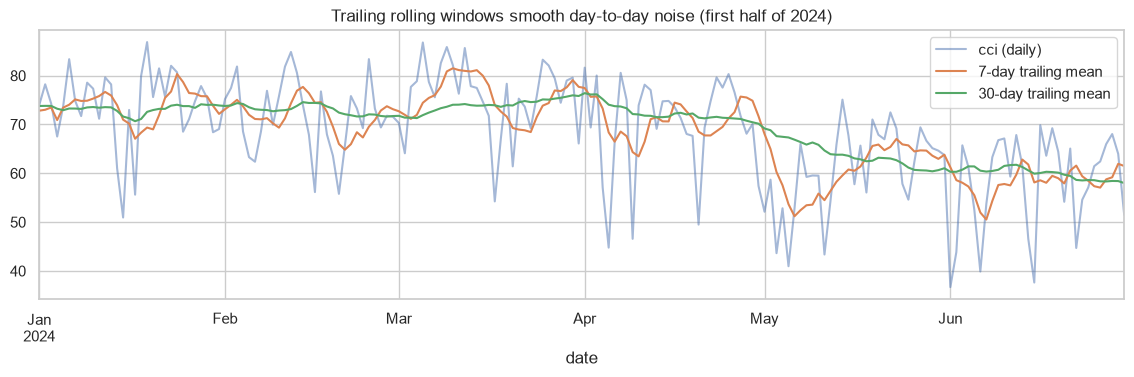

In [68]:
# <Student to fill this section>
roll_cols = [c for c in all_features if "_roll" in c]
print(len(roll_cols), "rolling features, e.g.", roll_cols[:5])
manual = daily_df["precipitation"].rolling(7).sum().reindex(model_table.index)
assert np.allclose(manual, model_table["precipitation_roll7_sum"])
sample = model_table.loc["2024-01":"2024-06"]
fig, ax = plt.subplots(figsize=(14, 3.5))
sample["cci"].plot(ax=ax, alpha=0.5, label="cci (daily)")
sample["cci_roll7_mean"].plot(ax=ax, label="7-day trailing mean")
sample["cci_roll30_mean"].plot(ax=ax, label="30-day trailing mean")
ax.legend(); ax.set_title("Trailing rolling windows smooth day-to-day noise (first half of 2024)"); plt.show()

In [69]:
# <Student to fill this section>
feature_engineering_2_explanations = """
Provide some explanations on why you believe it is important to create this feature and its impacts
"""

In [70]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "Cyclical calendar features"

> Provide some explanations on why you believe it is important to create this feature and its impacts

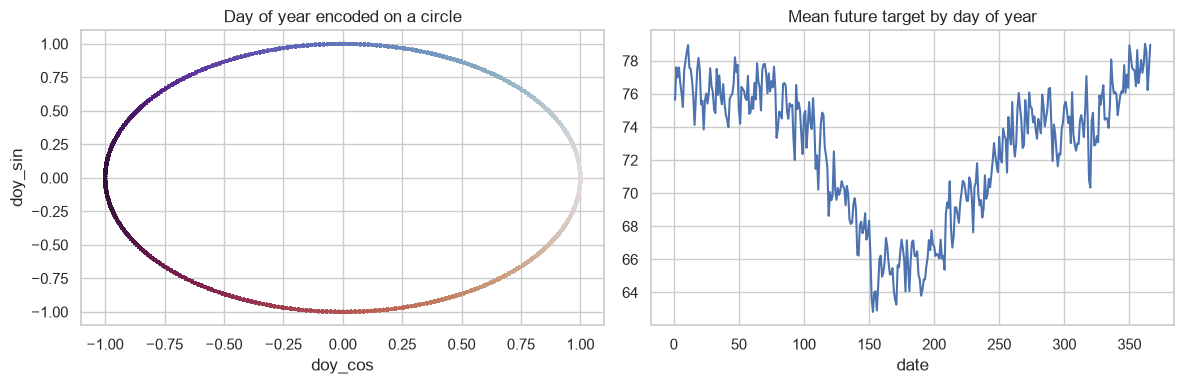

31 Dec and 1 Jan are neighbours: [-0.004  1.    -0.     1.   ] [0.017 1.    0.5   0.866]


In [71]:
# <Student to fill this section>
cal = model_table[["doy_sin", "doy_cos", "month_sin", "month_cos"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(cal["doy_cos"], cal["doy_sin"], c=model_table.index.dayofyear, cmap="twilight", s=3)
axes[0].set(title="Day of year encoded on a circle", xlabel="doy_cos", ylabel="doy_sin")
model_table.groupby(model_table.index.dayofyear)["target_cci_t1"].mean().plot(ax=axes[1], title="Mean future target by day of year")
plt.tight_layout(); plt.show()
print("31 Dec and 1 Jan are neighbours:", np.round(cal.loc["2019-12-31"].values, 3), np.round(cal.loc["2020-01-01"].values, 3))

In [72]:
# <Student to fill this section>
feature_engineering_n_explanations = """
Provide some explanations on why you believe it is important to create this feature and its impacts
"""

In [73]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.4 New Feature "Extra Open-Meteo predictors (dew point, pressure, radiation, wind components)"

In [74]:
# <Student to fill this section>
extra_vars = ("dew_point_2m", "surface_pressure", "shortwave_radiation", "wind_u", "wind_v")
without_extra = [c for c in features_list if not c.startswith(extra_vars)]
extra_check = {}
for name, cols in {"selected features": features_list, "without extra predictors": without_extra}.items():
    row = {"n_features": len(cols)}
    for target in TARGETS:
        tr, va = train_sel.dropna(subset=[target]), val_all.dropna(subset=[target])
        pred = np.clip(xgb_probe().fit(tr[cols], tr[target]).predict(va[cols]), 0, 100)
        row[f"val_mae_{target[-2:]}"] = regression_scores(va[target], pred)["mae"]
    extra_check[name] = row
pd.DataFrame(extra_check).T.round(3)

,n_features,val_mae_t1,val_mae_t2,val_mae_t3
selected features,89.0,6.046,7.466,7.825
without extra predictors,63.0,6.335,7.703,8.018


In [75]:
# <Student to fill this section>
feature_engineering_4_explanations = """
TBD
"""

In [76]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_4_explanations', value=feature_engineering_4_explanations)

---
## G. Data Preparation for Modeling


### G.1 Split Datasets

In [77]:
# <Student to fill this section>
data = model_table.dropna(subset=TARGETS)
train_df = data.loc[data.index < VAL_START]
val_df = data.loc[(data.index >= VAL_START) & (data.index < TEST_START)]
test_df = data.loc[data.index >= TEST_START]
assert test_df.index.max() < pd.Timestamp(PRODUCTION_CUTOFF)

X_train, y_train = train_df[features_list], train_df[TARGETS]
X_val, y_val = val_df[features_list], val_df[TARGETS]
X_test, y_test = test_df[features_list], test_df[TARGETS]

pd.DataFrame({
    name: {"first_input_date": df.index.min().date(), "last_input_date": df.index.max().date(), "rows": len(df)}
    for name, df in {"train": train_df, "validation": val_df, "test": test_df}.items()
}).T

,first_input_date,last_input_date,rows
train,1980-01-30,2019-12-31,14581
validation,2020-01-01,2022-12-31,1096
test,2023-01-01,2025-12-28,1093


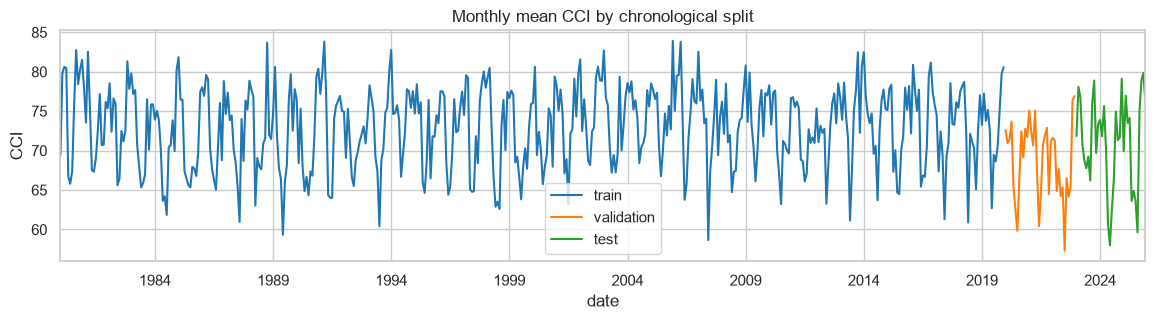

In [78]:
# <Student to fill this section>
fig, ax = plt.subplots(figsize=(14, 3))
for name, df, colour in [("train", train_df, "tab:blue"), ("validation", val_df, "tab:orange"), ("test", test_df, "tab:green")]:
    df["cci"].resample("ME").mean().plot(ax=ax, color=colour, label=name)
ax.set(title="Monthly mean CCI by chronological split", ylabel="CCI"); ax.legend(); plt.show()

In [79]:
# <Student to fill this section>
data_splitting_explanations = """
Provide some explanations on what is the best strategy to use for data splitting for this dataset
"""

In [80]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Remove rows without complete history or future target"

In [81]:
# <Student to fill this section>
print("Daily rows 1980-2025:", len(daily_df))
print("Dropped - not enough history for 30-day windows:", len(daily_df) - len(model_table),
      f"(first usable input date {model_table.index.min().date()})")
print("Dropped - target date falls in 2026 (production period):", len(model_table) - len(data),
      f"(last usable input date {data.index.max().date()})")

Daily rows 1980-2025: 16802
Dropped - not enough history for 30-day windows: 29 (first usable input date 1980-01-30)
Dropped - target date falls in 2026 (production period): 3 (last usable input date 2025-12-28)


In [82]:
# <Student to fill this section>
data_transformation_1_explanations = """
Provide some explanations on why you believe it is important to perform this data transformation and its impacts
"""

In [83]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "Imputation"

In [84]:
# <Student to fill this section>
print("Missing feature values - train / val / test:",
      int(X_train.isna().sum().sum()), int(X_val.isna().sum().sum()), int(X_test.isna().sum().sum()))

Missing feature values - train / val / test: 0 0 0


In [85]:
# <Student to fill this section>
data_transformation_2_explanations = """
Provide some explanations on why you believe it is important to perform this data transformation and its impacts
"""

In [86]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Scaling (linear models only)"

In [87]:
# <Student to fill this section>
# Only the linear comparison model needs scaling; the scaler sits inside the pipeline so it is
# fitted on the training rows only. Tree ensembles are invariant to monotonic rescaling.
ridge_pipeline = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
ridge_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


In [88]:
# <Student to fill this section>
data_transformation_3_explanations = """
Provide some explanations on why you believe it is important to perform this data transformation and its impacts
"""

In [89]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

---
## H. Save Datasets

In [90]:
# <Student to fill this section>

data_final_path = '../../data/processed/comfort_climate'
import os; os.makedirs(data_final_path, exist_ok=True)

In [91]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate


In [92]:
# <Student to fill this section>
def evaluate(y_true, y_pred) -> dict:
    """MAE, RMSE and R2 with predictions clipped to the valid CCI range."""
    return regression_scores(y_true, np.clip(y_pred, 0, 100))

In [93]:
# <Student to fill this section>
performance_metrics_explanations = """
TODO: MAE (primary, in CCI points), RMSE, R2 - reported per horizon.
Provide some explanations on why you believe the performance metrics you chose is appropriate
"""

In [94]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.0 Baselines

> Naive forecasts every model must beat

In [95]:
# <Student to fill this section>
baseline_rows = {}
for h, target in zip(HORIZONS, TARGETS):
    climatology = ClimatologyBaseline(horizon=h, by="dayofyear").fit(train_df.index, train_df[target])
    for split, df in {"val": val_df, "test": test_df}.items():
        baseline_rows[(f"t+{h}", "Persistence", split)] = evaluate(df[target], persistence_forecast(df["cci"]))
        baseline_rows[(f"t+{h}", "Climatology", split)] = evaluate(df[target], climatology.predict(df.index))
baselines = pd.DataFrame(baseline_rows).T
baselines.index.names = ["horizon", "model", "split"]
baselines["mae"].unstack(["split"]).round(3)

split                 test     val
horizon model                     
t+1     Climatology  7.528   8.192
        Persistence  7.470   7.236
t+2     Climatology  7.528   8.194
        Persistence  9.226   9.348
t+3     Climatology  7.527   8.197
        Persistence  9.865  10.330

In [96]:
# <Student to fill this section>
baseline_explanations = """
TODO: baseline scores on validation and test, and what they imply for the achievable uplift.
"""

In [97]:
# Do not modify this code
print_tile(size="h3", key='baseline_explanations', value=baseline_explanations)

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit


In [98]:
# <Student to fill this section>
candidates = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "RandomForest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.33,
                                                  n_jobs=-1, random_state=SEED),
    "LightGBM": lambda: LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                                      subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                                      random_state=SEED, verbose=-1),
    "XGBoost": xgb_probe,
}
comparison = {}
for name, make in candidates.items():
    for h, target in zip(HORIZONS, TARGETS):
        comparison[(name, f"t+{h}")] = evaluate(y_val[target], make().fit(X_train, y_train[target]).predict(X_val))["mae"]
comparison = pd.Series(comparison).unstack()
comparison.loc["Best baseline"] = baselines.xs("val", level="split")["mae"].groupby(level="horizon").min()
comparison.round(3)  # validation MAE

,t+1,t+2,t+3
LightGBM,6.111,7.511,7.837
RandomForest,6.169,7.441,7.847
Ridge,6.335,7.518,7.856
XGBoost,6.046,7.466,7.825
Best baseline,7.236,8.194,8.197


In [99]:
# <Student to fill this section>
algorithm_selection_explanations = """
Provide some explanations on why you believe this algorithm is a good fit
"""

In [100]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit


In [101]:
# <Student to fill this section>
# Hyperparameters were tuned with Optuna (TPE sampler) in weather_experiments/modeling/tune.py:
#   uv run python -m weather_experiments.modeling.tune --trials 12
# Each trial is scored on three expanding-window folds (score 2014-16, 2017-19, 2020-22), so settings are
# not tuned to a single period; the 2023-2025 test set is never used for selection.
tuning = pd.read_csv(REPORTS_DIR / "cci_tuning.csv")
tuned_params = json.loads((REPORTS_DIR / "cci_tuning_params.json").read_text())
best_params = {h: {m: tuned_params[f"{h} | raw+lags+calendar | {m}"] for m in ("XGBoost", "LightGBM")} for h in HORIZONS}
display(pd.DataFrame(best_params[1]).T)
tuning.pivot(index="model", columns="horizon", values="cv_mae").sort_values("t+1").round(3)  # mean MAE over the 3 folds

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,objective,num_leaves,min_child_samples
XGBoost,800,0.032352,3,1,0.655491,0.427628,9.31505,0.355001,reg:squarederror,NaN,NaN
LightGBM,600,0.020643,NaN,NaN,0.584226,0.578695,1.185556,NaN,regression,22,109


horizon,t+1,t+2,t+3
model,,,
XGBoost + LightGBM (mean),5.612,6.718,7.001
LightGBM,5.612,6.706,7.011
XGBoost + LightGBM + Ridge (mean),5.623,6.723,6.987
XGBoost,5.637,6.744,7.017
Ridge,5.870,6.860,7.063


In [102]:
# <Student to fill this section>
hyperparameters_selection_explanations = """
Explain why you are tuning these hyperparameters
"""

In [103]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [104]:
# <Student to fill this section>
def make_members(h):
    """Tuned XGBoost and LightGBM for horizon h; their predictions are averaged."""
    return [XGBRegressor(**best_params[h]["XGBoost"], random_state=SEED, n_jobs=-1),
            LGBMRegressor(**best_params[h]["LightGBM"], subsample_freq=1, random_state=SEED, verbose=-1)]

def fit_ensemble(h, X, y):
    return [m.fit(X, y) for m in make_members(h)]

def predict_ensemble(members, X):
    return np.clip(np.mean([m.predict(X) for m in members], axis=0), 0, 100)

MODEL_NAME = "tuned XGBoost + LightGBM"
results, val_preds, test_preds, eval_models = {}, {}, {}, {}
for h, target in zip(HORIZONS, TARGETS):
    val_preds[h] = predict_ensemble(fit_ensemble(h, X_train, y_train[target]), X_val)
    results[(f"t+{h}", MODEL_NAME, "val")] = evaluate(y_val[target], val_preds[h])
    # Test set used once: refit on train + validation with the chosen settings, then score 2023-2025.
    eval_models[h] = fit_ensemble(h, pd.concat([X_train, X_val]), pd.concat([y_train, y_val])[target])
    test_preds[h] = predict_ensemble(eval_models[h], X_test)
    results[(f"t+{h}", MODEL_NAME, "test")] = evaluate(y_test[target], test_preds[h])
results = pd.DataFrame(results).T
results.index.names = ["horizon", "model", "split"]
results.round(3)

mae    rmse     r2
horizon model                    split                      
t+1     tuned XGBoost + LightGBM val    6.068   8.343  0.402
                                 test   5.931   7.971  0.460
t+2     tuned XGBoost + LightGBM val    7.463  10.034  0.135
                                 test   6.976   9.310  0.264
t+3     tuned XGBoost + LightGBM val    7.895  10.598  0.037
                                 test   7.288   9.748  0.192

### J.4 Model Technical Performance

> Provide some explanations on model performance


In [105]:
# <Student to fill this section>
summary = pd.concat([baselines, results]).reset_index()
test_summary = summary[summary["split"] == "test"].pivot(index="model", columns="horizon", values="mae")
best_baseline = test_summary.loc[["Persistence", "Climatology"]].min()
test_summary.loc["Improvement vs best baseline (%)"] = (1 - test_summary.loc[MODEL_NAME] / best_baseline) * 100
print("Test MAE (2023-2025)")
test_summary.round(2)

Test MAE (2023-2025)


horizon,t+1,t+2,t+3
model,,,
Climatology,7.53,7.53,7.53
Persistence,7.47,9.23,9.87
tuned XGBoost + LightGBM,5.93,6.98,7.29
Improvement vs best baseline (%),20.60,7.32,3.18


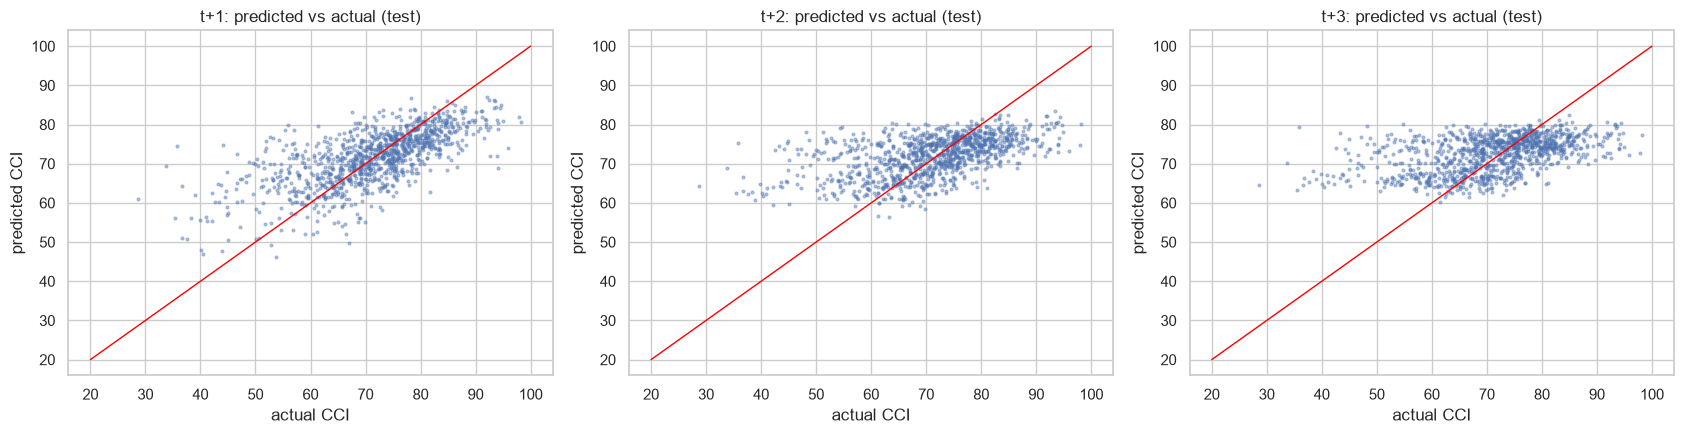

In [106]:
# <Student to fill this section>
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, h, target in zip(axes, HORIZONS, TARGETS):
    ax.scatter(y_test[target], test_preds[h], s=4, alpha=0.4)
    ax.plot([20, 100], [20, 100], c="red", lw=1)
    ax.set(title=f"t+{h}: predicted vs actual (test)", xlabel="actual CCI", ylabel="predicted CCI")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_pred_vs_actual.png", dpi=120); plt.show()

In [107]:
# <Student to fill this section>
abs_err = pd.DataFrame({f"t+{h}": np.abs(y_test[t].values - test_preds[h]) for h, t in zip(HORIZONS, TARGETS)}, index=X_test.index)
season = abs_err.index.month.map({12: "Summer", 1: "Summer", 2: "Summer", 3: "Autumn", 4: "Autumn", 5: "Autumn",
                                  6: "Winter", 7: "Winter", 8: "Winter", 9: "Spring", 10: "Spring", 11: "Spring"})
rain_next = pd.cut(daily_df["precipitation"].shift(-1).reindex(X_test.index), [-0.01, 0.1, 5, 1000], labels=["dry", "light", "heavy (>5 mm)"])
display(abs_err.groupby(season).mean().round(2).rename_axis("season (test MAE)"))
display(abs_err.groupby(rain_next, observed=True)["t+1"].agg(["mean", "count"]).round(2).rename_axis("rain on t+1"))

,t+1,t+2,t+3
season (test MAE),,,
Autumn,6.07,6.93,7.01
Spring,6.17,7.45,7.85
Summer,5.79,6.65,6.91
Winter,5.69,6.87,7.37


,mean,count
rain on t+1,,
dry,5.03,510
light,4.73,415
heavy (>5 mm),11.64,168


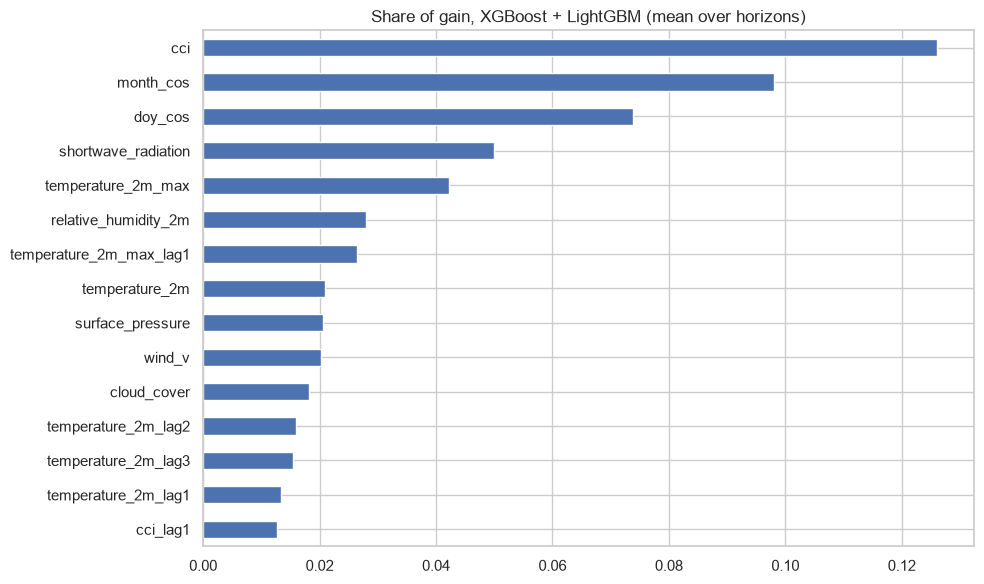

In [108]:
# <Student to fill this section>
def gain_share(members):
    xgb_gain = pd.Series(members[0].get_booster().get_score(importance_type="gain")).reindex(features_list).fillna(0)
    lgbm_gain = pd.Series(members[1].booster_.feature_importance("gain"), index=features_list)
    return (xgb_gain / xgb_gain.sum() + lgbm_gain / lgbm_gain.sum()) / 2

importance = pd.DataFrame({f"t+{h}": gain_share(eval_models[h]) for h in HORIZONS})
fig, ax = plt.subplots(figsize=(10, 6))
importance.mean(axis=1).sort_values().tail(15).plot(kind="barh", ax=ax, title="Share of gain, XGBoost + LightGBM (mean over horizons)")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "cci_feature_importance.png", dpi=120); plt.show()

In [109]:
# <Student to fill this section>
model_performance_explanations = """
Provide some explanations on model performance
"""

In [110]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view


In [111]:
# <Student to fill this section>
band_rows = {}
for h, target in zip(HORIZONS, TARGETS):
    actual_band = y_test[target].apply(cci_band)
    pred_band = pd.Series(test_preds[h], index=y_test.index).apply(cci_band)
    err = np.abs(y_test[target].values - test_preds[h])
    band_rows[f"t+{h}"] = {"same_band_%": (actual_band == pred_band).mean() * 100,
                           "error_within_5_%": (err <= 5).mean() * 100,
                           "error_over_15_%": (err > 15).mean() * 100}
display(pd.DataFrame(band_rows).round(1))
order = [label for _, label in CCI_BANDS]
pd.crosstab(y_test["target_cci_t1"].apply(cci_band), pd.Series(test_preds[1], index=y_test.index).apply(cci_band),
            rownames=["actual band (t+1)"], colnames=["predicted band"]).reindex(index=order, columns=order).fillna(0).astype(int)

,t+1,t+2,t+3
same_band_%,70.0,66.3,65.9
error_within_5_%,54.8,47.9,44.8
error_over_15_%,6.1,10.2,11.3


predicted band,Excellent outdoor conditions,Comfortable conditions,Moderate comfort,Poor comfort,Very poor comfort
actual band (t+1),,,,,
Excellent outdoor conditions,78,137,0,0,0
Comfortable conditions,28,657,30,0,0
Moderate comfort,0,123,30,0,0
Poor comfort,0,5,5,0,0
Very poor comfort,0,0,0,0,0


In [112]:
# <Student to fill this section>
business_impacts_explanations = """
Interpret the results of the experiments related to the business objective set earlier. Estimate the impacts of the incorrect results for the business (some results may have more impact compared to others)
"""

In [113]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes


In [114]:
# <Student to fill this section>
experiment_outcome = "TBD" # Either 'Hypothesis Confirmed', 'Hypothesis Partially Confirmed' or 'Hypothesis Rejected'

In [115]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [116]:
# <Student to fill this section>
experiment_results_explanations = """
Reflect on the outcome of the experiment and list the new insights you gained from it. Provide rationale for pursuing more experimentation with the current approach or call out if you think it is a dead end.
Given the results achieved and the overall objective of the project, list the potential next steps and experiments. For each of them assess the expected uplift or gains and rank them accordingly. If the experiment achieved the required outcome for the business, recommend the steps to deploy this solution into production.
"""

In [117]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)

---
## K. Save Model Artefacts

> Final pipeline and metadata used by the FastAPI service (`/model-metadata`)

In [118]:
# <Student to fill this section>
# Production models: refit on every labelled day up to 2025 with the tuned settings.
model_dir = MODELS_DIR / "comfort_climate"
model_dir.mkdir(parents=True, exist_ok=True)
X_all, y_all = data[features_list], data[TARGETS]
production_models = {f"t+{h}": fit_ensemble(h, X_all, y_all[t]) for h, t in zip(HORIZONS, TARGETS)}
artefact = {"models": production_models, "features": features_list, "horizons": list(HORIZONS),
            "output_range": [0, 100], "shiftguard_version": shiftguard.__version__}
joblib.dump(artefact, model_dir / "comfort_climate_ensemble.joblib", compress=3)

mean_importance = importance.mean(axis=1).sort_values(ascending=False)
metadata = {
    "target": "Climate Comfort Index",
    "prediction_type": "regression",
    "algorithm": "Ensemble: mean of XGBoost Regressor and LightGBM Regressor (one pair per horizon)",
    "forecast_horizon": "3 Days (t+1, t+2, t+3)",
    "output_range": [0, 100],
    "features": features_list,
    "feature_importance": {k: round(float(v), 4) for k, v in mean_importance.items()},
    "hyperparameters": {f"t+{h}": best_params[h] for h in HORIZONS},
    "metrics": {
        "test_2023_2025": {f"t+{h}": {k: round(v, 3) for k, v in results.loc[(f"t+{h}", MODEL_NAME, "test")].items()} for h in HORIZONS},
        "baselines_test_mae": {f"t+{h}": {m: round(baselines.loc[(f"t+{h}", m, "test"), "mae"], 3) for m in ["Persistence", "Climatology"]} for h in HORIZONS},
    },
    "training_period": f"{train_df.index.min().date()} to {train_df.index.max().date()}",
    "validation_period": f"{val_df.index.min().date()} to {val_df.index.max().date()}",
    "test_period": f"{test_df.index.min().date()} to {test_df.index.max().date()}",
    "production_model_trained_on": f"{data.index.min().date()} to {data.index.max().date()}",
    "data_source": "Open-Meteo Historical Weather API (archive, best_match), Sydney -33.8688, 151.2093",
    "shiftguard_version": shiftguard.__version__,
}
(model_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
sorted(p.name for p in model_dir.iterdir())

['.gitkeep', 'comfort_climate_ensemble.joblib', 'metadata.json']